In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
d1=pd.read_csv(r"C:\Users\mohit\Downloads\bike+sharing+dataset\hour.csv")
d1.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
d1.isnull().sum().sum()

np.int64(0)

In [5]:
d1.shape

(17379, 17)

In [6]:
import pandas as pd
df=pd.read_csv(r"C:\Users\mohit\Downloads\bike+sharing+dataset\hour.csv")
df["datetime"]=(pd.to_datetime(df["dteday"])+pd.to_timedelta(df["hr"],unit="h"))

In [7]:
print("duplicate hours:",df["datetime"].duplicated().sum())

duplicate hours: 0


In [8]:
all_hours=pd.date_range(df["datetime"].min(),df["datetime"].max(),freq="h")
missing_hours=all_hours.difference(df["datetime"])
print("expected hours:",len(all_hours))
print("recorded hours:",df["datetime"].nunique())
print("missing hours:",len(missing_hours))
print("missing pecentage:",round(len(missing_hours)/len(all_hours)*100,2))

expected hours: 17544
recorded hours: 17379
missing hours: 165
missing pecentage: 0.94


In [9]:
df_full=df.set_index("datetime")
df.set_index("datetime")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
datetime,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-12-31 19:00:00,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
2012-12-31 20:00:00,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
2012-12-31 21:00:00,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90


In [11]:
df_full=df_full.reindex(all_hours)
df_full.index.name="datetime"
df_full["was_missing_hour"]=df_full["cnt"].isna()

In [12]:
df_full["dteday"] = df_full.index.date
df_full["hr"] = df_full.index.hour
df_full["mnth"] = df_full.index.month
df_full["yr"] = df_full.index.year - 2011
df_full["weekday"] = (df_full.index.dayofweek + 1) % 7

print(df_full["was_missing_hour"].value_counts())

was_missing_hour
False    17379
True       165
Name: count, dtype: int64


In [13]:
print(df_full.isnull().sum())


instant             165
dteday                0
season              165
yr                    0
mnth                  0
hr                    0
holiday             165
weekday               0
workingday          165
weathersit          165
temp                165
atemp               165
hum                 165
windspeed           165
casual              165
registered          165
cnt                 165
was_missing_hour      0
dtype: int64


In [16]:
#chech which hour are missing frequently
missing_data=df_full[df_full["was_missing_hour"]==True]
print(missing_data["hr"].value_counts().sort_index())

hr
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3
Name: count, dtype: int64


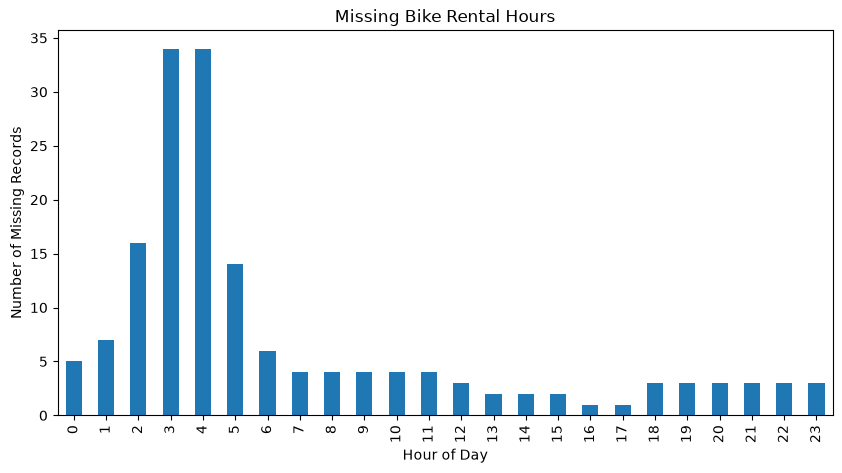

In [17]:
import matplotlib.pyplot as plt

missing_data["hr"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Missing Records")
plt.title("Missing Bike Rental Hours")
plt.show()

In [18]:
df_full[df_full["was_missing_hour"] == True].head(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,was_missing_hour
datetime,,,,,,,,,,,,,,,,,,
2011-01-02 05:00:00,NaN,2011-01-02,NaN,0,1,5,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-03 02:00:00,NaN,2011-01-03,NaN,0,1,2,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-03 03:00:00,NaN,2011-01-03,NaN,0,1,3,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-04 03:00:00,NaN,2011-01-04,NaN,0,1,3,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-05 03:00:00,NaN,2011-01-05,NaN,0,1,3,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-06 03:00:00,NaN,2011-01-06,NaN,0,1,3,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-07 03:00:00,NaN,2011-01-07,NaN,0,1,3,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-11 03:00:00,NaN,2011-01-11,NaN,0,1,3,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2011-01-11 04:00:00,NaN,2011-01-11,NaN,0,1,4,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


In [19]:
missing_data = df_full[df_full["was_missing_hour"]]

missing_dates = missing_data.index.normalize()

print(missing_dates.value_counts().sort_index())

datetime
2011-01-02     1
2011-01-03     2
2011-01-04     1
2011-01-05     1
2011-01-06     1
              ..
2012-10-30    13
2012-11-08     1
2012-11-29     1
2012-12-24     1
2012-12-25     1
Name: count, Length: 76, dtype: int64


In [20]:
df_model = df.copy()

print("Training dataset shape:", df_model.shape)

print("Missing values:")
print(df_model.isnull().sum())

Training dataset shape: (17379, 18)
Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
datetime      0
dtype: int64


In [21]:
# Create a separate dataset for ML
df_model = df.copy()

# Check its size
print("Original dataset:", df.shape)
print("ML dataset:", df_model.shape)

# Check missing values
print("\nMissing values:")
print(df_model.isnull().sum())

Original dataset: (17379, 18)
ML dataset: (17379, 18)

Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
datetime      0
dtype: int64


In [22]:
print("Duplicate rows:", df_model.duplicated().sum())

print(
    "Duplicate timestamps:",
    df_model["datetime"].duplicated().sum()
)

Duplicate rows: 0
Duplicate timestamps: 0


In [23]:
print(df_model.dtypes)

instant                int64
dteday                   str
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
datetime      datetime64[us]
dtype: object


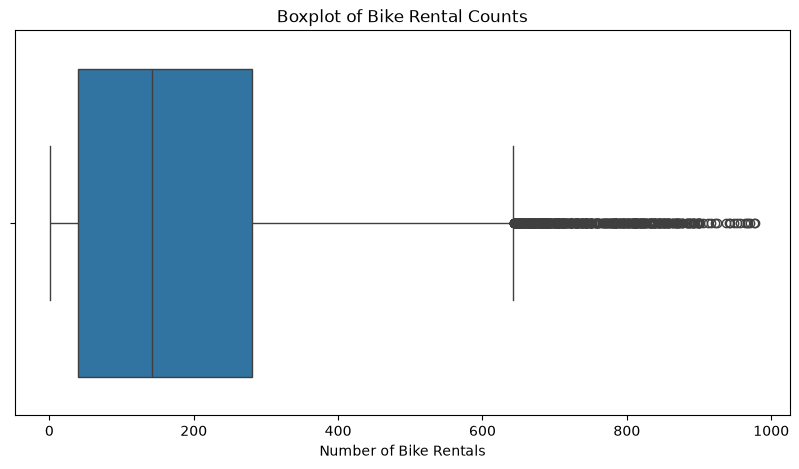

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(x=df_model["cnt"])

plt.title("Boxplot of Bike Rental Counts")
plt.xlabel("Number of Bike Rentals")

plt.show()

In [25]:
Q1 = df_model["cnt"].quantile(0.25)

Q3 = df_model["cnt"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 40.0
Q3: 281.0
IQR: 241.0
Lower bound: -321.5
Upper bound: 642.5


In [26]:
outliers = df_model[
    (df_model["cnt"] < lower_bound) |
    (df_model["cnt"] > upper_bound)
]

print("Number of outliers:", len(outliers))

print(outliers[["dteday", "hr", "cnt"]].head(10))

Number of outliers: 505
           dteday  hr  cnt
5536   2011-08-23  14  651
10358  2012-03-12  17  644
10359  2012-03-12  18  712
10382  2012-03-13  17  676
10383  2012-03-13  18  734
10397  2012-03-14   8  662
10406  2012-03-14  17  782
10407  2012-03-14  18  749
10430  2012-03-15  17  713
10431  2012-03-15  18  746


In [27]:
print("Maximum rentals:", df_model["cnt"].max())

print("Minimum rentals:", df_model["cnt"].min())

print("Average rentals:", df_model["cnt"].mean())

print("Median rentals:", df_model["cnt"].median())

Maximum rentals: 977
Minimum rentals: 1
Average rentals: 189.46308763450142
Median rentals: 142.0


In [28]:
print("Invalid hours:",
      (~df_model["hr"].between(0, 23)).sum())

print("Invalid months:",
      (~df_model["mnth"].between(1, 12)).sum())

print("Invalid weekdays:",
      (~df_model["weekday"].between(0, 6)).sum())

print("Invalid humidity:",
      (~df_model["hum"].between(0, 1)).sum())

print("Invalid rental counts:",
      (df_model["cnt"] < 0).sum())

Invalid hours: 0
Invalid months: 0
Invalid weekdays: 0
Invalid humidity: 0
Invalid rental counts: 0


In [29]:
invalid_total = df_model[
    df_model["cnt"] != (
        df_model["casual"] + df_model["registered"]
    )
]

print("Invalid rental totals:", len(invalid_total))

Invalid rental totals: 0


In [30]:
date_errors = (
    pd.to_datetime(df_model["dteday"]).dt.normalize()
    != df_model["datetime"].dt.normalize()
).sum()

hour_errors = (
    df_model["hr"] != df_model["datetime"].dt.hour
).sum()

print("Date mismatches:", date_errors)
print("Hour mismatches:", hour_errors)

Date mismatches: 0
Hour mismatches: 0


In [31]:
validation = {
    "Missing values": df_model.isnull().sum().sum(),

    "Duplicate rows": df_model.duplicated().sum(),

    "Duplicate timestamps":
        df_model["datetime"].duplicated().sum(),

    "Invalid hours":
        (~df_model["hr"].between(0, 23)).sum(),

    "Invalid months":
        (~df_model["mnth"].between(1, 12)).sum(),

    "Invalid humidity":
        (~df_model["hum"].between(0, 1)).sum(),

    "Negative rentals":
        (df_model["cnt"] < 0).sum(),

    "Incorrect rental totals":
        (df_model["cnt"] !=
         df_model["casual"] + df_model["registered"]).sum()
}

print(pd.Series(validation))

Missing values             0
Duplicate rows             0
Duplicate timestamps       0
Invalid hours              0
Invalid months             0
Invalid humidity           0
Negative rentals           0
Incorrect rental totals    0
dtype: int64


In [32]:
df_model.to_csv(
    "bike_rental_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [33]:
cleaned_df = pd.read_csv("bike_rental_cleaned.csv")

print("Rows:", cleaned_df.shape[0])
print("Columns:", cleaned_df.shape[1])

print("Missing values:",
      cleaned_df.isnull().sum().sum())

print(cleaned_df.head())

Rows: 17379
Columns: 18
Missing values: 0
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  \
0           1  0.24  0.2879  0.81        0.0       3          13   16   
1           1  0.22  0.2727  0.80        0.0       8          32   40   
2           1  0.22  0.2727  0.80        0.0       5          27   32   
3           1  0.24  0.2879  0.75        0.0       3          10   13   
4           1  0.24  0.2879  0.75        0.0       0           1    1   

              datetime  
0  2011-01-01 00:00:00  
